<a href="https://colab.research.google.com/github/angelbalderas11111/ray/blob/main/P3_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Librerías y configuración inicial**

In [11]:
from google.colab import files
print("Sube tus imágenes de prueba:")
uploaded = files.upload()

Sube tus imágenes de prueba:


Saving bolas-billar.png to bolas-billar (1).png
Saving pez-koi.png to pez-koi (3).png


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans

# Configuración para mostrar gráficos interactivos en el notebook
%matplotlib inline

**Representación de la imagen en el espacio RGB**

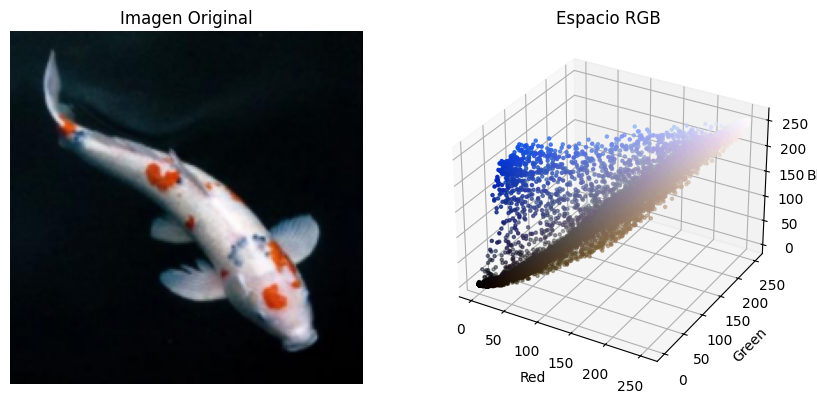

In [ ]:
# Cargar la imagen subida
baseimg = cv2.imread("pez-koi.png")
baseimg = cv2.resize(baseimg, (200, 200))

# Visualizar la imagen original y extraer los valores RGB de todos los píxeles
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(baseimg, cv2.COLOR_BGR2RGB))
plt.title("Imagen Original")
plt.axis('off')

# Gráfico 3D del espacio RGB via Matplotlib
ax = plt.subplot(1, 2, 2, projection='3d')
ax.scatter(
    baseimg[:, :, 0].flatten(),
    baseimg[:, :, 1].flatten(),
    baseimg[:, :, 2].flatten(),
    c=baseimg.reshape(-1, 3) / 255.0,
    marker='.'
)
ax.set_xlabel('Red')
ax.set_ylabel('Green')
ax.set_zlabel('Blue')
ax.set_title("Espacio RGB")
plt.show()

**Segmentación con K ($k=2, 4, 6$)**

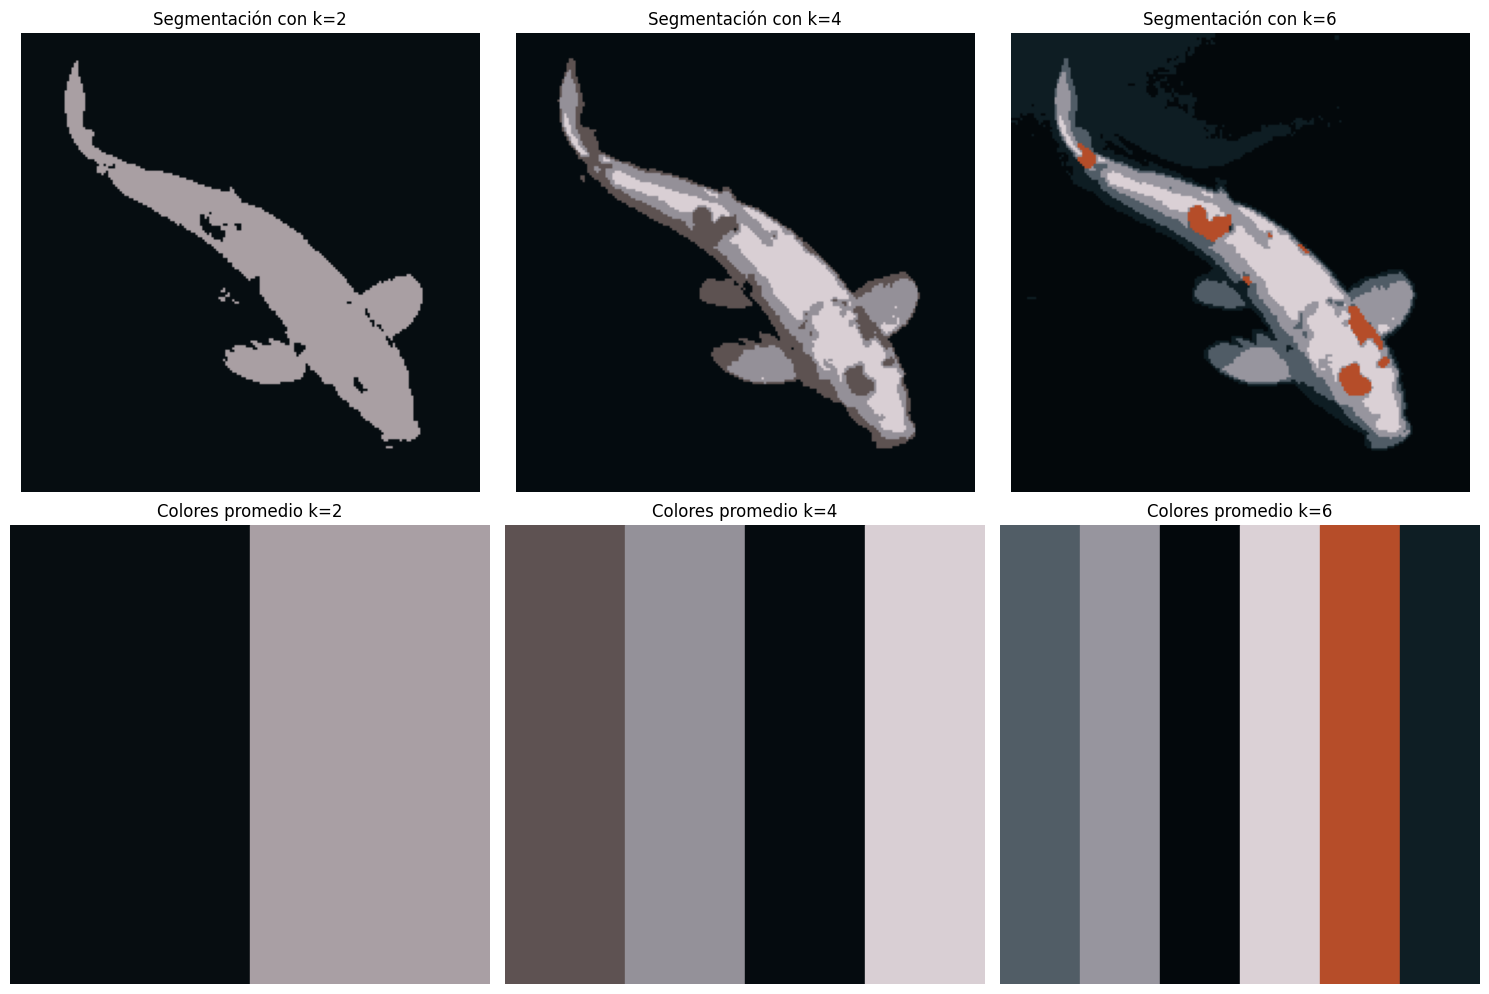

In [ ]:
# Realizar K-means para diferentes valores de k
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, k in enumerate([2, 4, 6]):
    # Aplicar K-means
    kmeans = KMeans(n_clusters=k, random_state=0).fit(baseimg.reshape(-1, 3))
    labels = kmeans.labels_

    # Reconstruir la imagen segmentada usando los centroides
    segmented_img = kmeans.cluster_centers_[labels].reshape(baseimg.shape).astype(np.uint8)

    # Mostrar la imagen segmentada
    axes[0, i].imshow(cv2.cvtColor(segmented_img, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title(f"Segmentación con k={k}")
    axes[0, i].axis('off')

    # Mostrar colores promedio de cada cluster
    colors = kmeans.cluster_centers_ / 255.0
    colors_rgb = colors[:, [2, 1, 0]]  # BGR a RGB para Matplotlib

    for j in range(k):
        rect = mpatches.Rectangle((j/k, 0), 1/k, 1, color=colors_rgb[j])
        axes[1, i].add_patch(rect)

    axes[1, i].set_xlim(0, 1)
    axes[1, i].set_ylim(0, 1)
    axes[1, i].set_title(f"Colores promedio k={k}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

**Aplicación práctica con otra imagen**

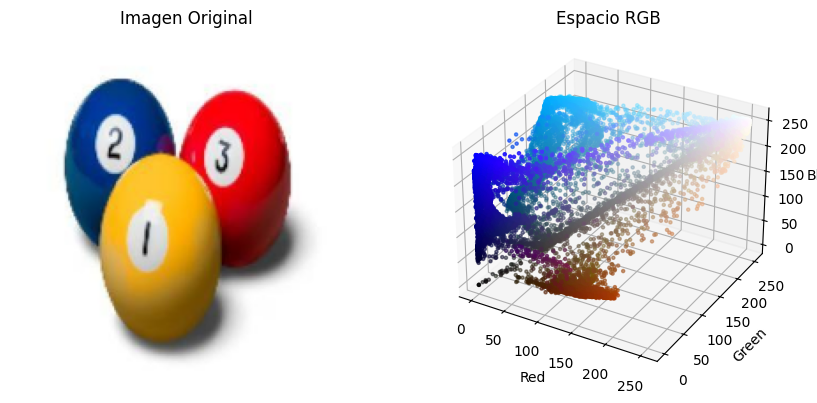

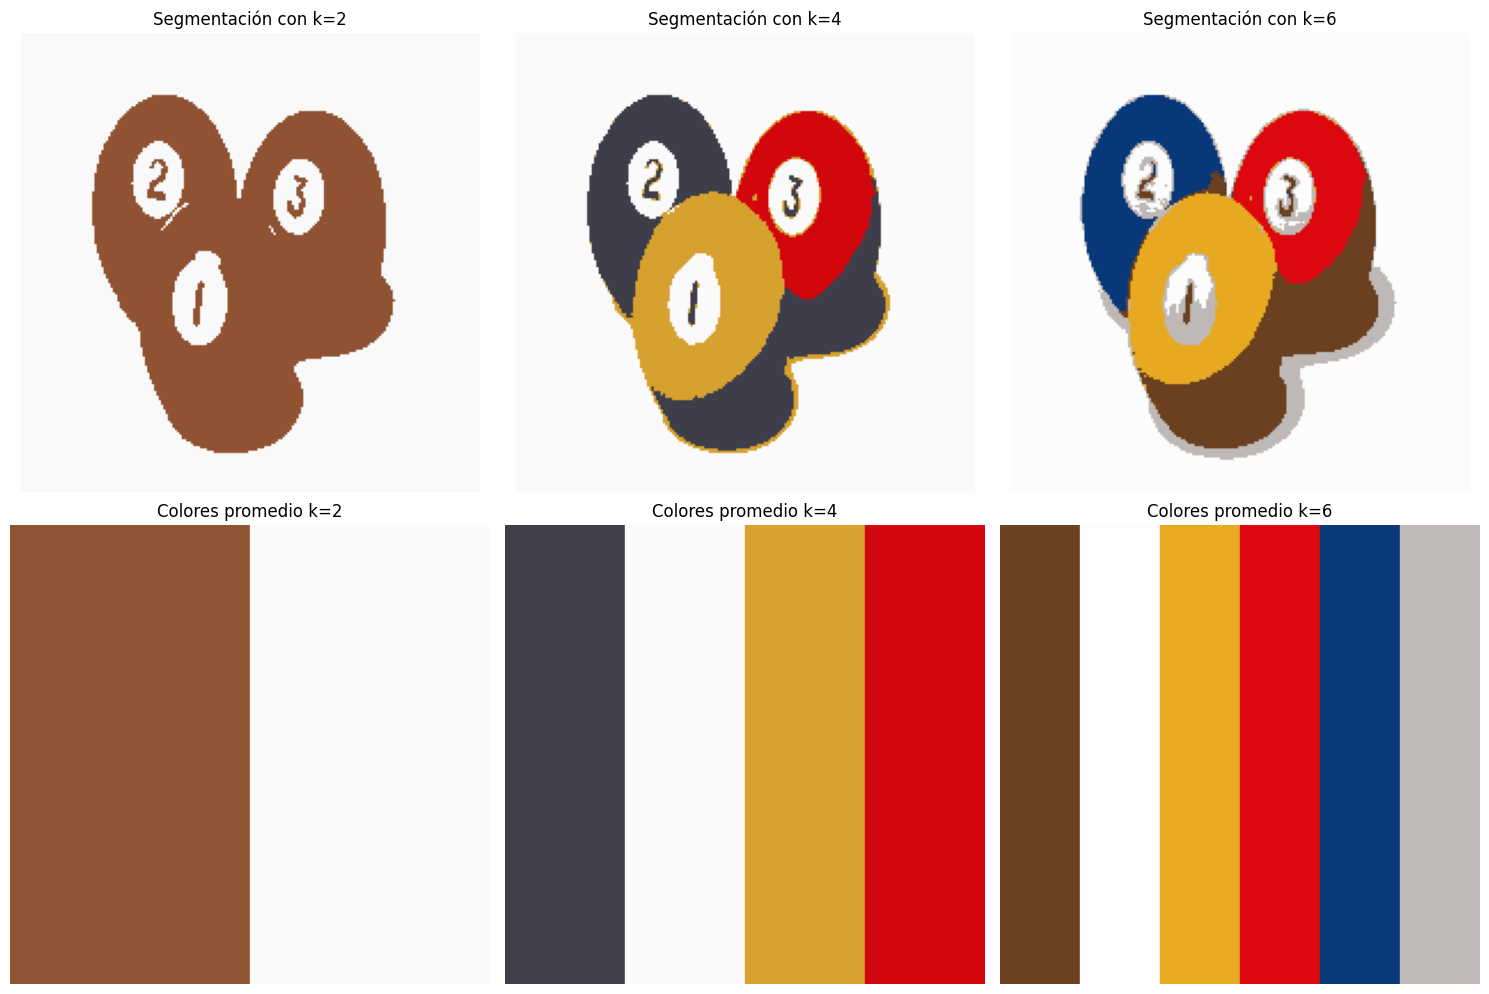

In [12]:
# Cargar la segunda imagen para la aplicación práctica
img_practica = cv2.imread("bolas-billar.png")
img_practica = cv2.resize(img_practica, (200, 200))

# Visualizar la segunda imagen y su espacio RGB
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_practica, cv2.COLOR_BGR2RGB))
plt.title("Imagen Original")
plt.axis('off')

ax = plt.subplot(1, 2, 2, projection='3d')
ax.scatter(
    img_practica[:, :, 0].flatten(),
    img_practica[:, :, 1].flatten(),
    img_practica[:, :, 2].flatten(),
    c=img_practica.reshape(-1, 3) / 255.0,
    marker='.'
)
ax.set_xlabel('Red')
ax.set_ylabel('Green')
ax.set_zlabel('Blue')
ax.set_title("Espacio RGB")
plt.show()

# Aplicar K-means (k=2, 4, 6) para la aplicación práctica
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, k in enumerate([2, 4, 6]):
    kmeans = KMeans(n_clusters=k, random_state=0).fit(img_practica.reshape(-1, 3))
    labels = kmeans.labels_
    segmented_img = kmeans.cluster_centers_[labels].reshape(img_practica.shape).astype(np.uint8)

    axes[0, i].imshow(cv2.cvtColor(segmented_img, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title(f"Segmentación con k={k}")
    axes[0, i].axis('off')

    colors = kmeans.cluster_centers_ / 255.0
    colors_rgb = colors[:, [2, 1, 0]]

    for j in range(k):
        rect = mpatches.Rectangle((j/k, 0), 1/k, 1, color=colors_rgb[j])
        axes[1, i].add_patch(rect)

    axes[1, i].set_xlim(0, 1)
    axes[1, i].set_ylim(0, 1)
    axes[1, i].set_title(f"Colores promedio k={k}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()